<a href="https://colab.research.google.com/github/26ehahn-gif/exo-transit1/blob/main/exoplanet_baby.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Install lightkurve and photutils prior to running

In [6]:
# PART 1: FINDING AND DOWNLOADING A TARGET PIXEL FILE

# step 1 -> imports
import numpy as np
import lightkurve as lk
import matplotlib.pyplot as plt
from astropy.io import fits
from astropy.visualization import simple_norm
from photutils.aperture import CircularAperture, aperture_photometry
from astropy.time import Time
from scipy.signal import savgol_filter

In [7]:
# step 2 -> decide which sector to use

# OPTION 1 -> look through parameters for each sector individually to compare

target = "TIC 271971130"

# search all available SPOC TESS target pixel files
sr = lk.search_targetpixelfile(target, mission="TESS", author="SPOC")
print(sr)

# get the sector numbers that exist
sectors = np.array(sr.table["sequence_number"])
print("Available sectors:", sectors)

mask = (sectors >= 0) & (sectors < 34) # change to narrow

# download and inspect each sector one by one
for row in sr.table[mask]:
    sector = row["sequence_number"]
    print(f"\n--- Sector {sector} ---")

    try:
        tpf = sr[sectors.tolist().index(sector)].download()
        lc = tpf.to_lightcurve(aperture_mask="pipeline").remove_nans()

        # cleaning
        lc = lc.remove_outliers(sigma=5)
        flat = lc.flatten(window_length=301)

        # summary numbers
        print(f"Cadences: {len(flat)}")
        print(f"Median flux: {np.nanmedian(flat.flux.value):.6f}")
        print(f"Std flux: {np.nanstd(flat.flux.value):.6f}") # want less than .01

    except Exception as e:
        print(f"Could not load sector {sector}: {e}")

SearchResult containing 53 data products.

 #     mission     year author exptime target_name distance
                                  s                 arcsec 
--- -------------- ---- ------ ------- ----------- --------
  0 TESS Sector 01 2018   SPOC     120   271971130      0.0
  1 TESS Sector 02 2018   SPOC     120   271971130      0.0
  2 TESS Sector 03 2018   SPOC     120   271971130      0.0
  3 TESS Sector 04 2018   SPOC     120   271971130      0.0
  4 TESS Sector 05 2018   SPOC     120   271971130      0.0
  5 TESS Sector 06 2018   SPOC     120   271971130      0.0
  6 TESS Sector 07 2019   SPOC     120   271971130      0.0
  7 TESS Sector 08 2019   SPOC     120   271971130      0.0
  8 TESS Sector 09 2019   SPOC     120   271971130      0.0
  9 TESS Sector 10 2019   SPOC     120   271971130      0.0
 10 TESS Sector 11 2019   SPOC     120   271971130      0.0
 11 TESS Sector 12 2019   SPOC     120   271971130      0.0
 12 TESS Sector 13 2019   SPOC     120   271971130      0

Cadences: 13454
Median flux: 0.999866
Std flux: 0.009221

--- Sector 4 ---
Cadences: 15456
Median flux: 0.999732
Std flux: 0.010756

--- Sector 5 ---
Cadences: 17641
Median flux: 0.999970
Std flux: 0.009033

--- Sector 6 ---
Cadences: 14681
Median flux: 0.999976
Std flux: 0.007605

--- Sector 7 ---
Cadences: 16341
Median flux: 0.999961
Std flux: 0.007919

--- Sector 8 ---
Cadences: 12756
Median flux: 0.999924
Std flux: 0.008759

--- Sector 9 ---
Cadences: 16318
Median flux: 1.000110
Std flux: 0.007625

--- Sector 10 ---
Cadences: 17656
Median flux: 0.999961
Std flux: 0.009115

--- Sector 11 ---
Cadences: 18181
Median flux: 0.999948
Std flux: 0.009134

--- Sector 12 ---
Cadences: 18862
Median flux: 0.999972
Std flux: 0.008289

--- Sector 13 ---
Cadences: 19438
Median flux: 0.999919
Std flux: 0.008172

--- Sector 27 ---
Cadences: 100732
Median flux: 0.999969
Std flux: 0.020074

--- Sector 27 ---
Cadences: 100732
Median flux: 0.999969
Std flux: 0.020074

--- Sector 29 ---
Cadences: 17904


SearchResult containing 53 data products.

 #     mission     year author exptime target_name distance
                                  s                 arcsec 
--- -------------- ---- ------ ------- ----------- --------
  0 TESS Sector 01 2018   SPOC     120   271971130      0.0
  1 TESS Sector 02 2018   SPOC     120   271971130      0.0
  2 TESS Sector 03 2018   SPOC     120   271971130      0.0
  3 TESS Sector 04 2018   SPOC     120   271971130      0.0
  4 TESS Sector 05 2018   SPOC     120   271971130      0.0
  5 TESS Sector 06 2018   SPOC     120   271971130      0.0
  6 TESS Sector 07 2019   SPOC     120   271971130      0.0
  7 TESS Sector 08 2019   SPOC     120   271971130      0.0
  8 TESS Sector 09 2019   SPOC     120   271971130      0.0
  9 TESS Sector 10 2019   SPOC     120   271971130      0.0
 10 TESS Sector 11 2019   SPOC     120   271971130      0.0
 11 TESS Sector 12 2019   SPOC     120   271971130      0.0
 12 TESS Sector 13 2019   SPOC     120   271971130      0

    Std flux: 0.008893
  --- Evaluating Sector 3 (Index 2) ---
    Std flux: 0.009221
  --- Evaluating Sector 4 (Index 3) ---
    Std flux: 0.010756
  --- Evaluating Sector 5 (Index 4) ---
    Std flux: 0.009033
  --- Evaluating Sector 6 (Index 5) ---
    Std flux: 0.007605
    New best sector found: Sector 6 with Std flux: 0.007605
  --- Evaluating Sector 7 (Index 6) ---
    Std flux: 0.007919
  --- Evaluating Sector 8 (Index 7) ---
    Std flux: 0.008759
  --- Evaluating Sector 9 (Index 8) ---
    Std flux: 0.007625
  --- Evaluating Sector 10 (Index 9) ---
    Std flux: 0.009115
  --- Evaluating Sector 11 (Index 10) ---
    Std flux: 0.009134
  --- Evaluating Sector 12 (Index 11) ---
    Std flux: 0.008289
  --- Evaluating Sector 13 (Index 12) ---
    Std flux: 0.008172
  --- Evaluating Sector 27 (Index 13) ---
    Std flux: 0.020074
  --- Evaluating Sector 27 (Index 14) ---
    Std flux: 0.008381
  --- Evaluating Sector 29 (Index 15) ---
    Std flux: 0.009595
  --- Evaluating Secto

    Std flux: 0.008203
  --- Evaluating Sector 36 (Index 22) ---
    Std flux: 0.008171
  --- Evaluating Sector 37 (Index 23) ---
    Std flux: 0.007525
  --- Evaluating Sector 39 (Index 24) ---
    Std flux: 0.007828
  --- Evaluating Sector 61 (Index 25) ---
    Std flux: 0.022333
  --- Evaluating Sector 62 (Index 26) ---
    Std flux: 0.021822
  --- Evaluating Sector 63 (Index 27) ---
    Std flux: 0.017886
  --- Evaluating Sector 64 (Index 28) ---
    Std flux: 0.019086
  --- Evaluating Sector 65 (Index 29) ---
    Std flux: 0.021734
  --- Evaluating Sector 66 (Index 30) ---
    Std flux: 0.019325
  --- Evaluating Sector 67 (Index 31) ---
    Std flux: 0.023752
  --- Evaluating Sector 68 (Index 32) ---
    Std flux: 0.023868
  --- Evaluating Sector 69 (Index 33) ---
    Std flux: 0.025891
  --- Evaluating Sector 61 (Index 34) ---
    Std flux: 0.009144
  --- Evaluating Sector 62 (Index 35) ---
    Std flux: 0.009134
  --- Evaluating Sector 63 (Index 36) ---
    Std flux: 0.007395
  

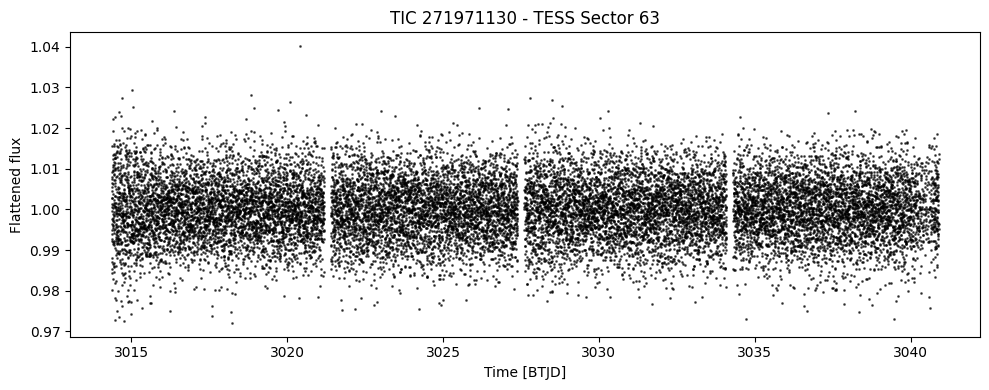

In [8]:
# OPTION 2 -> find the cleanest sector programmatically
target = "TIC 271971130"

# search all available SPOC TESS target pixel files
sr = lk.search_targetpixelfile(target, mission="TESS", author="SPOC")
print(sr)

# get the sector numbers that exist
sectors = np.array(sr.table["sequence_number"])
print("Available sectors:", sectors)

# search algorithm
min_std_flux = np.inf
best_sector_index = -1
best_sector_number = -1

print("\nEvaluating all available sectors to find the cleanest data...")
# iterate through all search results to find the best sector
for i, row in enumerate(sr.table):
    current_sector = row["sequence_number"]
    print(f"  --- Evaluating Sector {current_sector} (Index {i}) ---")
    try:
        # download TPF temporarily to assess data quality
        tpf_temp = sr[i].download()
        lc_temp = tpf_temp.to_lightcurve(aperture_mask="pipeline").remove_nans()

        # cleaning
        lc_temp = lc_temp.remove_outliers(sigma=5)
        flat_temp = lc_temp.flatten(window_length=301)

        std_flux_temp = np.nanstd(flat_temp.flux.value)
        print(f"    Std flux: {std_flux_temp:.6f}")

        # Update if a cleaner sector is found
        if std_flux_temp < min_std_flux:
            min_std_flux = std_flux_temp
            best_sector_index = i
            best_sector_number = current_sector
            print(f"    New best sector found: Sector {best_sector_number} with Std flux: {min_std_flux:.6f}")

    except Exception as e:
        print(f"    Could not load or process sector {current_sector}: {e}")

print(f"\n--- Best sector chosen: Sector {best_sector_number} (Index {best_sector_index}) with Std flux: {min_std_flux:.6f} ---\n")

# use the identified best sector for the rest of the cell
sector = best_sector_number
sector_index = best_sector_index

# download just that one (the best one)
tpf = sr[sector_index].download()
lc = tpf.to_lightcurve(aperture_mask="pipeline").remove_nans()

# cleaning
lc = lc.remove_outliers(sigma=5)
flat = lc.flatten(window_length=301)

# summary numbers
print(f"Cadences: {len(flat)}")
print(f"Median flux: {np.nanmedian(flat.flux.value):.6f}")
print(f"Std flux: {np.nanstd(flat.flux.value):.6f}")

# plot
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(flat.time.value, flat.flux.value, "k.", ms=2, alpha=0.6)
ax.set_title(f"TIC 271971130 - TESS Sector {sector}")
ax.set_xlabel("Time [BTJD]")
ax.set_ylabel("Flattened flux")
plt.tight_layout()
plt.show()

Available sectors: [ 1  2  3  4  5  6  7  8  9 10 11 12 13 27 27 29 30 31 32 33 34 35 36 37
 39 61 62 63 64 65 66 67 68 69 61 62 63 64 65 66 67 68 69 87 88 89 90 93
 94 95 96 97 98]
Cadences: 111464
Median flux: 1.000044
Std flux: 0.017886


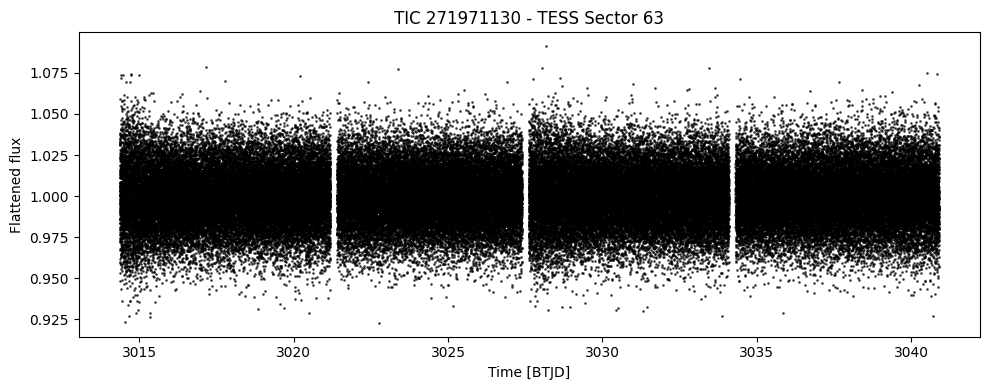

In [ ]:
# OPTION 3 -> show only one sector
target = "TIC 000000000"

# search all available SPOC TESS target pixel files
sr = lk.search_targetpixelfile(target, mission="TESS", author="SPOC")

# get the sector numbers that exist
sectors = np.array(sr.table["sequence_number"])
print("Available sectors:", sectors)

#choose a sector
sector = 00

# find the index of that sector
best_sector_index = sectors.tolist().index(sector)

# download just the one
tpf = sr[sectors.tolist().index(sector)].download()
lc = tpf.to_lightcurve(aperture_mask="pipeline").remove_nans()

# cleaning
lc = lc.remove_outliers(sigma=5)
flat = lc.flatten(window_length=301)

# summary numbers
print(f"Cadences: {len(flat)}")
print(f"Median flux: {np.nanmedian(flat.flux.value):.6f}")
print(f"Std flux: {np.nanstd(flat.flux.value):.6f}")

# plot
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(flat.time.value, flat.flux.value, "k.", ms=2, alpha=0.6)
ax.set_title(f"TIC 271971130 - TESS Sector {sector}")
ax.set_xlabel("Time [BTJD]")
ax.set_ylabel("Flattened flux")
plt.tight_layout()
plt.show()

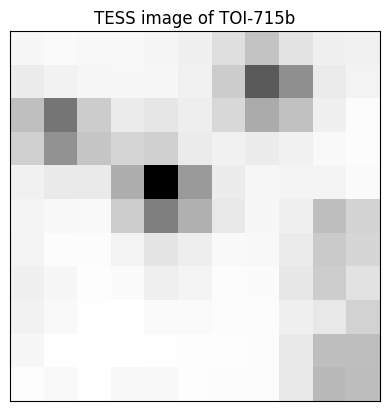

In [9]:
# step 3 -> downloading data locally
tpf = sr[best_sector_index].download() # This is the lightkurve TPF object

# tpf.path is not strictly needed if we use attributes of the lightkurve object
# no need for with fits.open(tpf.path) as hdus:
tpf_hdr = tpf.hdu[1].header # Get the header directly from the lightkurve object's HDU list

# step 4 -> getting a clear target pixel image
texp = tpf_hdr["FRAMETIM"] * tpf_hdr["NUM_FRM"] # gets exposure time - multiply each frametime by num of frames
texp /= 60.0 * 60.0 * 24.0 # converts seconds to days

# Extract raw time and flux values from the lightkurve TPF object
raw_time_values = tpf.time.value
raw_flux_values = tpf.flux
raw_quality_values = tpf.quality

m = np.any(np.isfinite(raw_flux_values), axis=(1, 2)) & (raw_quality_values == 0) # quality filtering
''' how the quality filtering works (pay attention guys):
        m -> boolean mask (array of boolean values) for each timestamp/frame
        np.isfinite(flux) -> checks each pixel value. true = real, false = NaN or Inf
        np.any(np.isfinite(flux), axis=(1, 2)) -> collapse axis1 (rows) and axis2 (columns)
            for each in axis0 (time) = one true or false -> "in each image, is any pixel finite?"
            SO it only removes an image if no single pixel value is finite = entire image is trash
        tpf["QUALITY"] == 0 -> 0 bits flagged, no problems whatsoever
'''
ref_time = 0.5 * (np.min(raw_time_values[m])+np.max(raw_time_values[m])) # time centering, ref_time = midpoint.
    # time[m] -> time array with only true values, only showing good images
time = np.ascontiguousarray(raw_time_values[m] - ref_time, dtype=np.float64)
flux = np.ascontiguousarray(raw_flux_values[m], dtype=np.float64)
    # ascontiguousarray = continuous with no gaps from removed data (m)
    # float64 = 64 bits, more precise

# step 5 -> showing the pixel image!!
med_img = np.median(flux, axis=0)
    # collapses axis0 (time), and displays median brightness for each pixel across all frames
plt.figure()
plt.imshow(med_img.T, cmap="gray_r") # cmap=gray_r = reversed grayscale colormap
plt.title("TESS image of TOI-715b")
plt.xticks([])
plt.yticks([]);

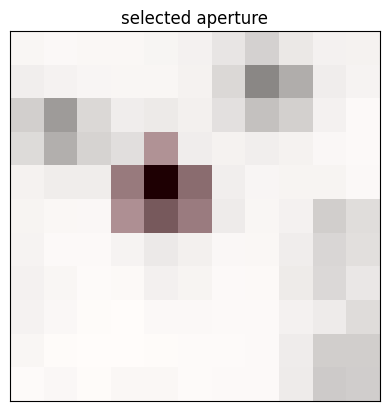

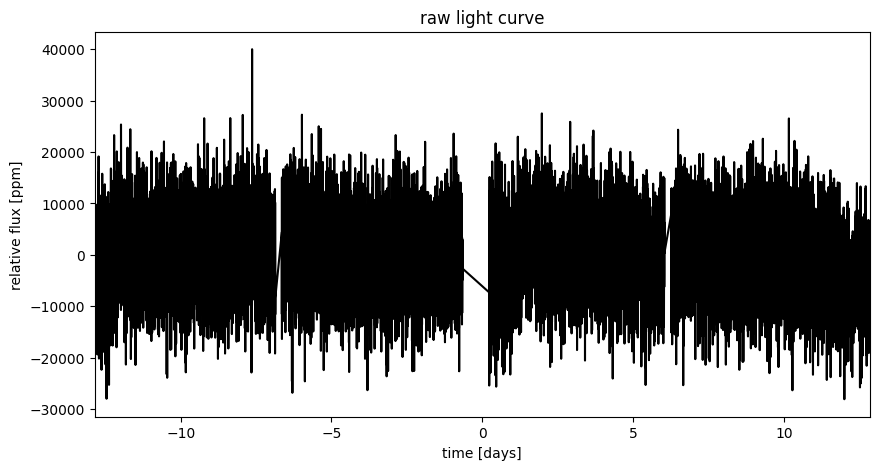

In [12]:
# PART 2: APERTURE SELECTION

pix_mask = tpf.create_threshold_mask(threshold=2) # adjust threshold as needed

# step 5 -> plot selected aperture
plt.figure()
plt.imshow(med_img.T, cmap="gray_r")
# Ensure pix_mask is boolean for imshow overlay
plt.imshow(pix_mask.T, cmap="Reds", alpha=0.3)
plt.title("selected aperture")
plt.xticks([])
plt.yticks([]);

# step 6 -> plot raw light curve
sap_flux = np.sum(flux[:, pix_mask], axis=-1)
sap_flux = (sap_flux / np.median(sap_flux) - 1) * 1e6 # Corrected: 1e3 to 1e6 for ppm
plt.figure(figsize=(10, 5))
plt.plot(time, sap_flux, "k")
plt.xlabel("time [days]")
plt.ylabel("relative flux [ppm]") # Label changed to ppm
plt.title("raw light curve")
plt.xlim(time.min(), time.max());

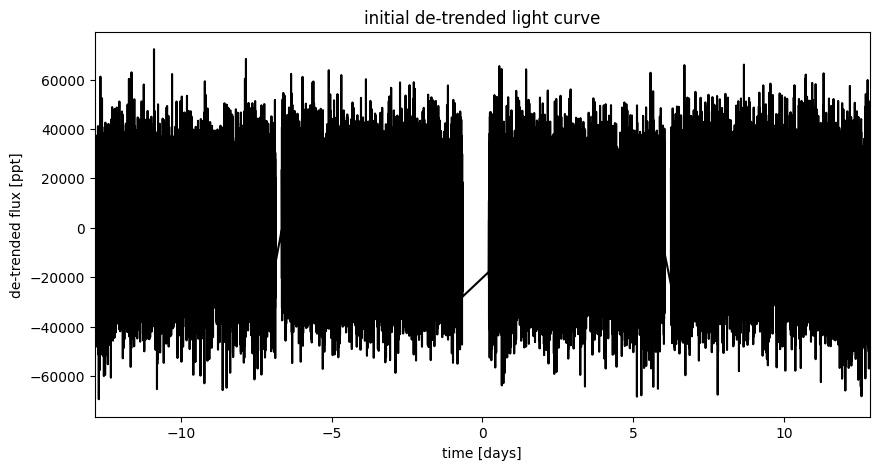

In [ ]:
# PART 3: DETRENDING

# step 1 -> build first order PLD basis
X_pld = np.reshape(flux[:, pix_mask], (len(flux), -1))
X_pld = X_pld / np.sum(flux[:, pix_mask], axis=-1)[:, None]

# step 2 -> build second order PLD basis and run PCA to reduce number of dimensions
X2_pld = np.reshape(X_pld[:, None, :] * X_pld[:, :, None], (len(flux), -1))
U, _, _ = np.linalg.svd(X2_pld, full_matrices=False)
X2_pld = U[:, :X_pld.shape[1]]

# step 3 -> construct design matrix and fit for PLD model
X_pld = np.concatenate((np.ones((len(flux), 1)), X_pld, X2_pld), axis=-1)
XTX = np.dot(X_pld.T, X_pld)
w_pld = np.linalg.solve(XTX, np.dot(X_pld.T, sap_flux))
pld_flux = np.dot(X_pld, w_pld)
detrended_flux = sap_flux - pld_flux

# step 4 -> plot the de-trended light curve
plt.figure(figsize=(10, 5))
plt.plot(time, detrended_flux, "k")
plt.xlabel("time [days]")
plt.ylabel("de-trended flux [ppt]")
plt.title("initial de-trended light curve")
plt.xlim(time.min(), time.max());

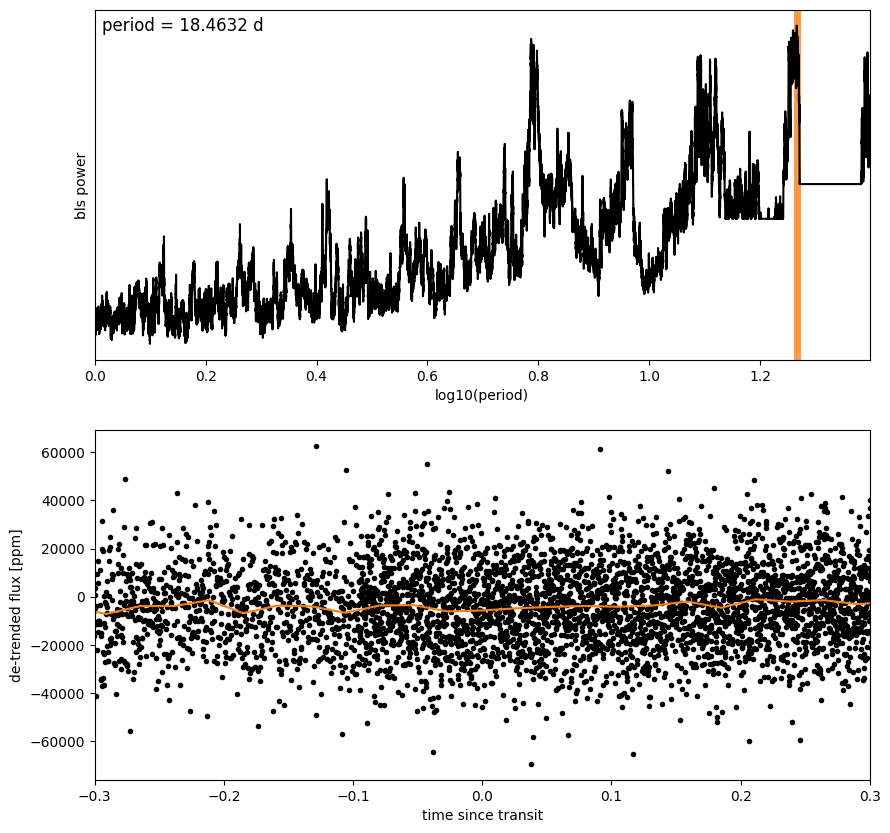

In [ ]:
# PART 4: TRANSIT SEARCH

from astropy.timeseries import BoxLeastSquares

period_grid = np.exp(np.linspace(np.log(1), np.log(25), 50000))

# Use the Savitzky-Golay detrended flux for the BLS search
bls = BoxLeastSquares(time, detrended_flux)
# Smaller planet transits often have shorter durations. Let's search a range.
durations = np.linspace(0.02, 0.1, 10) # Search from 0.48 hours to 2.4 hours (0.1 days)
bls_power = bls.power(period_grid, durations, oversample=20)

# step 1 -> save the highest peak as the planet candidate
index = np.argmax(bls_power.power)
bls_period = bls_power.period[index]
bls_t0 = bls_power.transit_time[index]
bls_depth = bls_power.depth[index]
# Use the duration found by BLS for the transit mask
bls_duration = bls_power.duration[index]
transit_mask = bls.transit_mask(time, bls_period, bls_duration, bls_t0)

fig, axes = plt.subplots(2, 1, figsize=(10, 10))

# step 2 -> plot the periodogram
ax = axes[0]
ax.axvline(np.log10(bls_period), color="C1", lw=5, alpha=0.8)
ax.plot(np.log10(bls_power.period), bls_power.power, "k")
ax.annotate("period = {0:.4f} d".format(bls_period),
            (0, 1), xycoords="axes fraction",
            xytext=(5, -5), textcoords="offset points",
            va="top", ha="left", fontsize=12)
ax.set_ylabel("bls power")
ax.set_yticks([])
ax.set_xlim(np.log10(period_grid.min()), np.log10(period_grid.max()))
ax.set_xlabel("log10(period)")

# step 3 -> plot the folded transit
ax = axes[1]
x_fold = (time - bls_t0 + 0.5*bls_period)%bls_period - 0.5*bls_period
m = np.abs(x_fold) < 0.4
# Use the detrended flux for plotting
ax.plot(x_fold[m], detrended_flux[m], ".k")

# step 4 -> overplot the phase binned light curve
bins = np.linspace(-0.41, 0.41, 32)
denom, _ = np.histogram(x_fold, bins)
# Use the detrended flux for binning weights
num, _ = np.histogram(x_fold, bins, weights=detrended_flux)
denom[num == 0] = 1.0
ax.plot(0.5*(bins[1:] + bins[:-1]), num / denom, color="C1")

ax.set_xlim(-0.3, 0.3)
ax.set_ylabel("de-trended flux [ppm]")
ax.set_xlabel("time since transit");

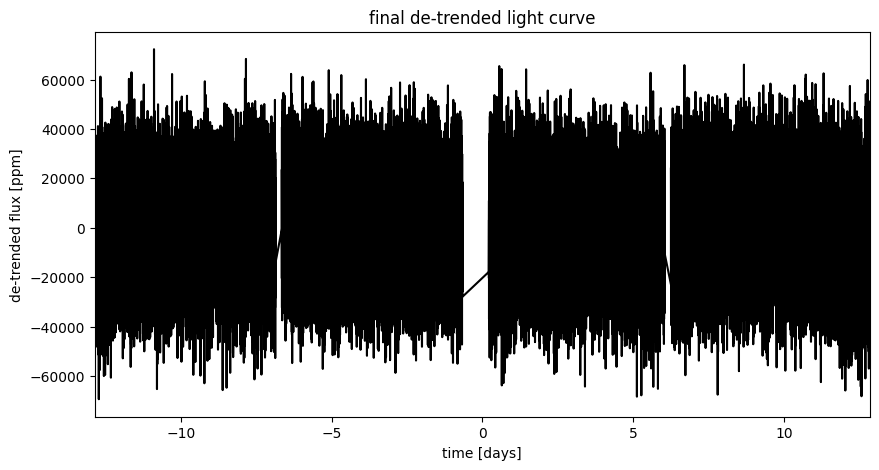

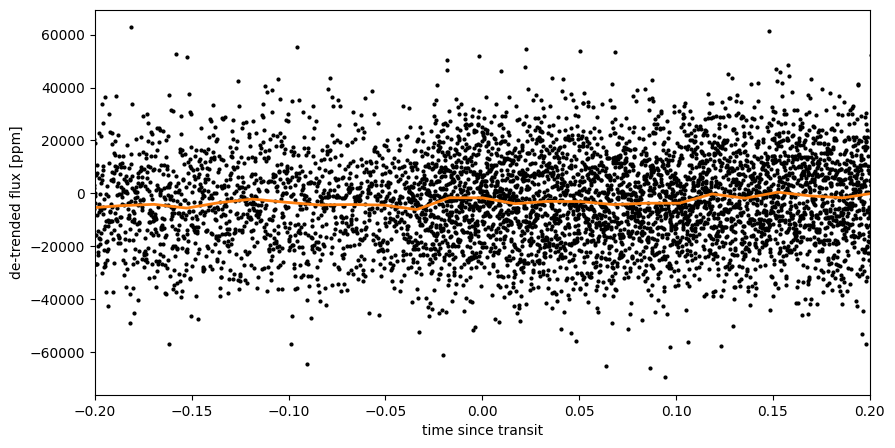

In [ ]:
# PART 5: CONFIRM NOT OVERFIT

# step 1 -> final detrend lightcurve
x = np.ascontiguousarray(time, dtype=np.float64)
y = np.ascontiguousarray(detrended_flux, dtype=np.float64)
plt.figure(figsize=(10, 5))
plt.plot(time, y, "k")
plt.xlabel("time [days]")
plt.ylabel("de-trended flux [ppm]")
plt.title("final de-trended light curve")
plt.xlim(time.min(), time.max());

# step 2 -> check for residual transit signal (less relevant with SG filter)
plt.figure(figsize=(10, 5))
x_fold_check = (x - bls_t0 + 0.5*bls_period) % bls_period - 0.5*bls_period
m_check = np.abs(x_fold_check) < 0.3
plt.plot(x_fold_check[m_check], y[m_check], ".k", ms=4)
bins_check = np.linspace(-0.5, 0.5, 60)
denom_check, _ = np.histogram(x_fold_check, bins_check)
num_check, _ = np.histogram(x_fold_check, bins_check, weights=y)
denom_check[num_check == 0] = 1.0
plt.plot(0.5*(bins_check[1:] + bins_check[:-1]), num_check / denom_check, color="C1", lw=2)
plt.xlim(-0.2, 0.2)
plt.xlabel("time since transit")
plt.ylabel("de-trended flux [ppm]");

In [14]:
import numpy as np
from scipy.optimize import curve_fit

# step 1 -> Phase-fold the light curve using the BLS ephemeris
# put all timestamps into a window centered on the transit. repeated transits line up at phase = 0.
x = np.ascontiguousarray(time, dtype=np.float64)

x_fold = (x - bls_t0 + 0.5 * bls_period) % bls_period - 0.5 * bls_period

# step 2 -> keep only points near the transit
# reduces the fit to the part of the light curve that actually contains the transit signal.
transit_window = np.abs(x_fold) < 0.3
x_transit = x_fold[transit_window]
y_transit = y[transit_window] # Use the detrended flux 'y'

# step 3 -> define a simple trapezoid transit model
def trapezoid_transit(t, depth, duration, ingress, t0):
    # flux should represent a dip, so the depth should be negative relative to the baseline (0)
    flux = np.zeros_like(t)

    for i, ti in enumerate(t):
        dt = np.abs(ti - t0)

        # ingress: linearly ramp down to full depth
        if dt < ingress / 2:
            flux[i] = -depth * (dt / (ingress / 2))

        # full transit: flat bottom
        elif dt < duration / 2:
            flux[i] = -depth

        # egress: linearly ramp back up
        elif dt < (duration + ingress) / 2:
            flux[i] = -depth * (1 - (dt - duration / 2) / (ingress / 2))

        # outside transit: flux stays at 0
        else:
            flux[i] = 0.0

    return flux

# step 4 -> fit the trapezoid model
# Use bls_depth as an initial guess for the depth (it's already positive, so we use it directly)
p0 = [bls_depth, bls_duration, 0.005, 0.0] # Initial guess for depth, duration (using bls_duration), ingress, t0

# parameter bounds to keep the fit physically reasonable.
# Depth should be positive, duration and ingress must be positive.
bounds = ([0.0, 0.01, 0.001, -0.1], # Lower bounds
          [50000.0, 0.2, 0.05, 0.1])  # Upper bounds (adjust depth upper if needed, e.g., to 50000 ppm)

fit_success = False
try:
    popt, pcov = curve_fit(
        trapezoid_transit,
        x_transit,
        y_transit,
        p0=p0,
        bounds=bounds,
        maxfev=10000
    )

    perr = np.sqrt(np.diag(pcov))

    depth_fit, duration_fit, ingress_fit, t0_fit = popt
    depth_err, duration_err, ingress_err, t0_err = perr
    fit_success = True

except Exception as e:
    print(f"Fit failed: {e}")

# step 5 -> bin the folded data for plotting
bins = np.linspace(-0.3, 0.3, 60)
counts, _ = np.histogram(x_transit, bins)
weighted_sum, _ = np.histogram(x_transit, bins, weights=y_transit)

# avoid division by zero in empty bins
counts[counts == 0] = 1

x_bin = 0.5 * (bins[1:] + bins[:-1])
y_bin = weighted_sum / counts

# step 6 -> plot
fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(x_transit, y_transit, ".k", alpha=0.3, ms=3, label="data")
ax.plot(x_bin, y_bin, "o", color="C0", ms=5, label="binned")

if fit_success:
    t_model = np.linspace(-0.3, 0.3, 1000)
    y_model = trapezoid_transit(t_model, *popt)
    ax.plot(t_model, y_model, color="C1", lw=2, label="trapezoid fit")

ax.set_xlabel("time since transit [days]")
ax.set_ylabel("de-trended flux [ppm]") # Changed to ppm
ax.set_title("phase-folded transit")
ax.set_xlim(-0.25, 0.25)
ax.legend()
plt.tight_layout()
plt.show()

# step 7 -> print fitted parameters
print("=" * 40)
print("FITTED TRANSIT PARAMETERS")
print("=" * 40)
print(f"Period (from BLS):   {bls_period:.6f} days")
print(f"t0 (from BLS):       {bls_t0:.6f} days")

if fit_success:
    print(f"Depth:               {depth_fit:.4f} \u00b1 {depth_err:.4f} ppm") # Changed to ppm
    print(f"Duration:            {duration_fit * 24:.3f} \u00b1 {duration_err * 24:.3f} hours")
    print(f"Ingress/egress:      {ingress_fit * 24 * 60:.1f} \u00b1 {ingress_err * 24 * 60:.1f} minutes")

    # approximate radius ratio from transit depth: depth_fraction \u2248 (Rp/Rs)^2
    ror = np.sqrt(depth_fit / 1e6)  # ppm -> fractional flux (1e6)
    ror_err = 0.5 * ror * (depth_err / depth_fit)

    print(f"Radius ratio Rp/Rs:  {ror:.4f} \u00b1 {ror_err:.4f}")

NameError: name 'bls_t0' is not defined